In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import hvplot.xarray
# from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import curve_fit

[-3.23147764e-14  7.84354749e-14  2.71079952e-11 -2.62028313e-11
 -8.54364545e-09  2.86815044e-09  1.28327228e-06 -1.09404061e-07
 -8.40995647e-05  3.12901138e-06 -6.75085195e-04 -1.57923054e-03
  9.98652527e-01]


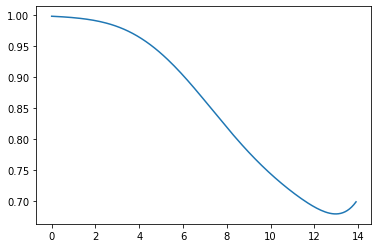

In [3]:
calib_dir = 'C:/Users/RalphGroup/Documents/group_code/daedalus_control/calibrations/'
field_correction_coeff= np.loadtxt(calib_dir + 'daedalus_fieldratio_calib.csv', delimiter=',')
field_correction_calib = np.poly1d(field_correction_coeff)
R = np.arange(0, 14, 0.1)
plt.plot(R, field_correction_calib(R))
print(field_correction_coeff)

In [4]:
measured = pd.read_csv('./2024-07-17/RadialPositionVersusField_daedalus_radialPolar_calib_A000.0_2024-07-17_5.csv', comment = '#', index_col = 'theta')
ds = xr.Dataset(measured)
ds = ds.where(ds.R < 14, drop=True)

[-1.01777118e-11  8.73273595e-10 -3.25449125e-08  6.88424669e-07
 -9.06072649e-06  7.65499707e-05 -4.15117124e-04  1.42418609e-03
 -3.03141088e-03  3.38846022e-03 -1.76901593e-03 -2.26326842e-03
  9.99984423e-01]


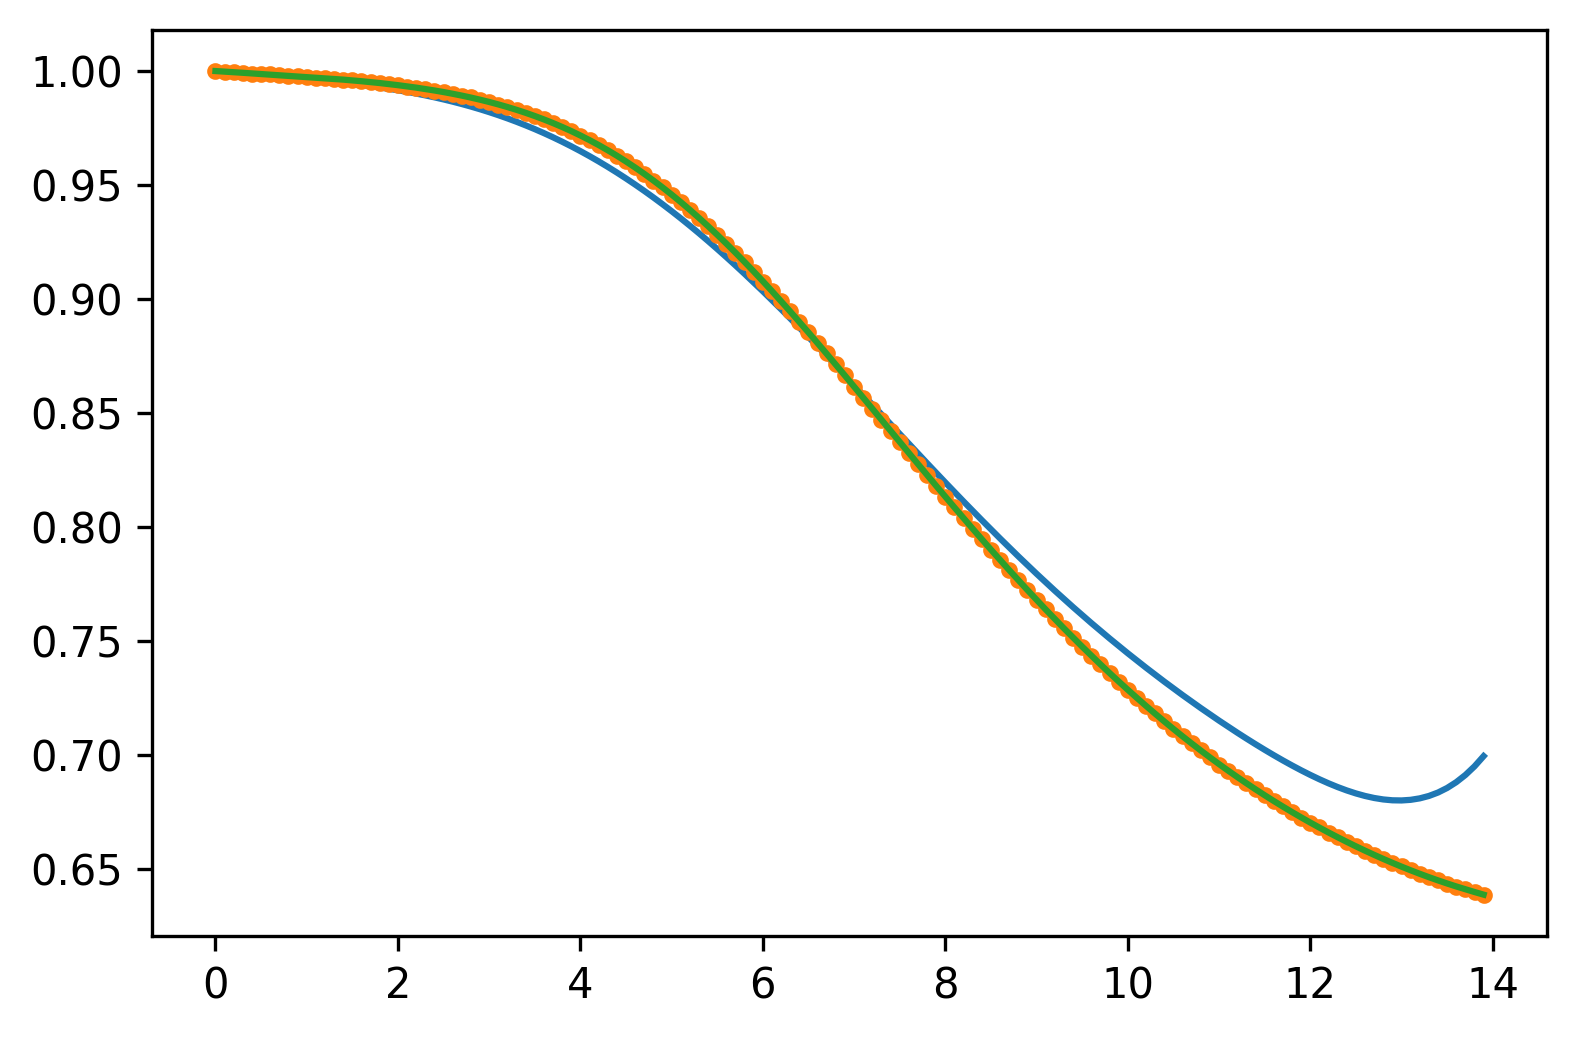

In [17]:
plt.figure(dpi=300)
plt.plot(R, field_correction_calib(R))
plt.plot(ds['R'], ds['B']/ds['B'].max(), '.')

field_correction_coeff_new = np.polyfit(ds['R'], ds['B']/ds['B'].max(), 12)
print(field_correction_coeff_new)
field_correction_calib_new = np.poly1d(field_correction_coeff_new)
plt.plot(R, field_correction_calib_new(R))